<a href="https://colab.research.google.com/github/Anastetikc/Math_Stat/blob/main/%D0%9A%D0%BE%D0%BF%D0%B8%D1%8F_%D0%B1%D0%BB%D0%BE%D0%BA%D0%BD%D0%BE%D1%82%D0%B0_%225_nonparametric_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sterolose/sirius-statistics-2026/blob/main/notebooks/5_nonparametric.ipynb)

## Семинар 5. Непараметрические методы, мощность теста, минимально обнаруживаемый эффект

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

В этот раз используем датасет [Exercise](https://github.com/mwaskom/seaborn-data/blob/master/exercise.csv). Датасет содержит 90 измерений пульса 30 участников. Каждый участник выполнял только один вид активности, во время которой его пульс измеряли трижды: на 1-й, 15-й и 30-й минутах от начала. Участники также были разделены на две группы по диете.

Столбцы содержат следующие переменные:
- `id` — идентификатор участника;
- `diet` — диета: `low fat` и `no fat`;
- `pulse` — пульс, ударов в минуту;
- `time` — время измерения: `1 min`, `15 min`, `30 min`;
- `kind` — вид активности: `rest`, `walking`, `running`.

In [ ]:
df = sns.load_dataset("exercise")
df.head(2)

,Unnamed: 0,id,diet,pulse,time,kind
0,0,1,low fat,85,1 min,rest
1,1,1,low fat,85,15 min,rest


Удалим лишнюю колонку.

In [ ]:
df = df.drop(columns=df.columns[0])
df.head(2)

,id,diet,pulse,time,kind
0,1,low fat,85,1 min,rest
1,1,low fat,85,15 min,rest


Посчитаем число наблюдений в каждой подгруппе

In [ ]:
df.value_counts(["kind", "diet", "time"]).to_frame(name="n")

n
kind    diet    time     
rest    no fat  1 min   5
                15 min  5
                30 min  5
        low fat 1 min   5
                15 min  5
                30 min  5
walking no fat  1 min   5
                15 min  5
                30 min  5
        low fat 1 min   5
                15 min  5
                30 min  5
running no fat  1 min   5
                15 min  5
                30 min  5
        low fat 1 min   5
                15 min  5
                30 min  5

Как обычно, во всех заданиях используем уровень значимости $\alpha = 0.05$ и двусторонние альтернативы.

### Задание 1

Постройте гистограмму распределения пульса для всей выборки.

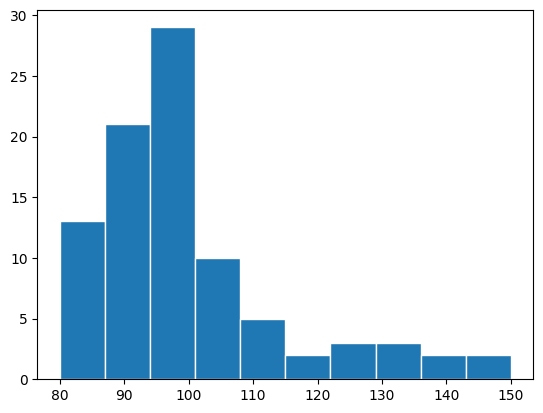

In [ ]:
plt.hist(df.pulse, edgecolor="white")
plt.show()

Постройте QQ-plot для оценки нормальности также по всему датасету.

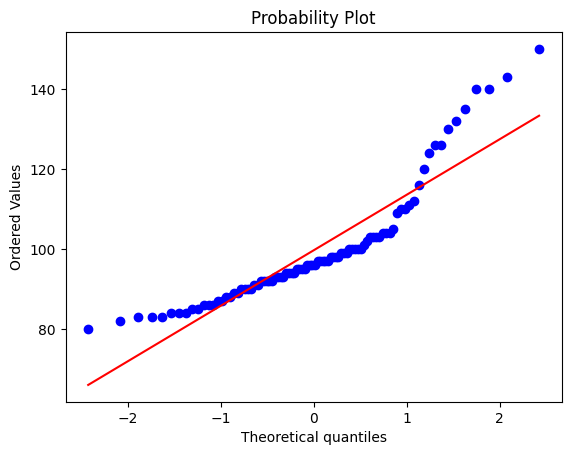

In [ ]:
stats.probplot(df.pulse, dist="norm", plot = plt)
plt.show()

Выполните тест Шапиро — Уилка для подвыборок, образованных категориями переменной `kind`.

In [ ]:
for kind in ('rest', 'walking', 'running'):
  group = df[df.kind == kind]
  values = group.pulse
  result = stats.shapiro(values)
  print(f'{kind}: {result.statistic:.2f} {result.pvalue:.3g}')

rest: 0.95 0.216
walking: 0.96 0.404
running: 0.93 0.0457


### Задание 2

Построим диаграммы размаха пульса для разных видов активности и диеты.

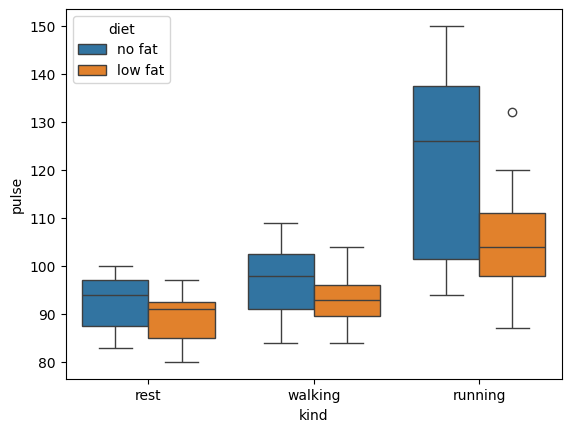

In [ ]:
sns.boxplot(df, x="kind", y="pulse", hue="diet")
plt.show()

С помощью теста Манна — Уитни проверим, различается ли статистически пульс в покое и при ходьбе.

In [ ]:
rest = df.loc[df["kind"] == "rest", "pulse"]
walking = df.loc[df["kind"] == "walking", "pulse"]

result = stats.mannwhitneyu(rest, walking)
f"U = {result.statistic}, p-value = {result.pvalue:.3g}"

'U = 288.5, p-value = 0.0171'

In [ ]:
result.statistic / (len(rest) * len(walking))

np.float64(0.32055555555555554)

С помощью теста Манна — Уитни оцените, различается ли статистически пульс у людей с разной диетой.

In [ ]:
nofat = df.loc[df["diet"] == "no fat", "pulse"]
lowfat = df.loc[df["diet"] == "low fat", "pulse"]

result = stats.mannwhitneyu(nofat, lowfat)
f"U = {result.statistic}, p-value = {result.pvalue:.3g}"

'U = 1272.5, p-value = 0.0361'

In [ ]:
result.statistic / (len(nofat) * len(lowfat))

np.float64(0.6283950617283951)

Сравните с параметрическим аналогом.

In [ ]:
stats.ttest_ind(nofat, lowfat, equal_var=True)

TtestResult(statistic=np.float64(2.457504273642696), pvalue=np.float64(0.015951606961272263), df=np.float64(88.0))

При каких условиях результат теста Манна — Уитни можно интерпретировать как различие медиан?

### Задание 3

Теперь построим диаграммы размаха пульса для разных видов активности и времени измерения.

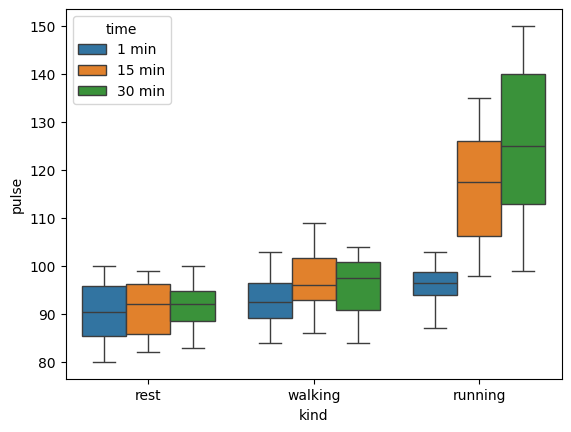

In [ ]:
sns.boxplot(df, x="kind", y="pulse", hue="time")
plt.show()

Оценим, различается ли пульс через 15 и 30 минут у одного и того же человека, исключив группу покоя.  
Сперва отфильтруем датафрейм, а затем переведем его в "wide"-формат.

In [ ]:
group = df.loc[df["kind"] != "rest"]
group_wide = group.pivot(
    index="id", columns="time", values="pulse",
)
group_wide.head(2)

time,1 min,15 min,30 min
id,,,
11,86,86,84
12,93,103,104


Проверьте, изменился ли систематически пульс с помощью парного теста Вилкоксона (`stats.wilcoxon`). Сравните результат с  параметрическим аналогом.

In [ ]:
stats.wilcoxon(group_wide['30 min'], group_wide['15 min'])
stats.ttest_rel(group_wide['15 min'], group_wide['30 min'])

TtestResult(statistic=np.float64(-1.511009942803624), pvalue=np.float64(0.14723933049726848), df=np.int64(19))

### Задание 4

Предприятие внедряет новый производственный процесс, который должен снизить загрязнение близлежащего водоема. Концентрация загрязнителя в пробах воды считается нормально распределенной со стандартным отклонением **12 мг/л**. Средняя текущая концентрация составляет **80 мг/л**. Требуется спланировать исследование так, чтобы с вероятностью **80%** обнаружить изменение средней концентрации не менее чем на **20%** при уровне значимости **0.05**. Сколько проб нужно взять в контрольном эксперименте и при тестировании нового процесса, если сравнение проводится с помощью двухвыборочного t-теста? Ответ округлите вверх до целого числа.

Для t-теста в `statsmodels` существует специальный класс, который значительно упрощает решение.

In [ ]:
from statsmodels.stats.power import TTestIndPower

diff = 80 * 0.2
effect = diff / 12

size = TTestIndPower().solve_power(
    effect_size=effect,
    power=0.8,
    alpha=0.05,
)
int(np.ceil(size))

10

Какое минимальное количество проб необходимо взять для решения предыдущей задачи, если предположить, что концентрация распределена логнормально? Исходные параметры распределения (среднее и стандартное отклонение логарифма величины) принять равными **2.5** и **0.75**, а желаемое изменение первого — **0.5**.

Для такой постановки нет аналитического решения. Проведите симуляцию **1000** виртуальных экспериментов для каждого объема выборки, используя тест Манна — Уитни. Изобразите изменение частоты обнаружений значимого эффекта на графике.

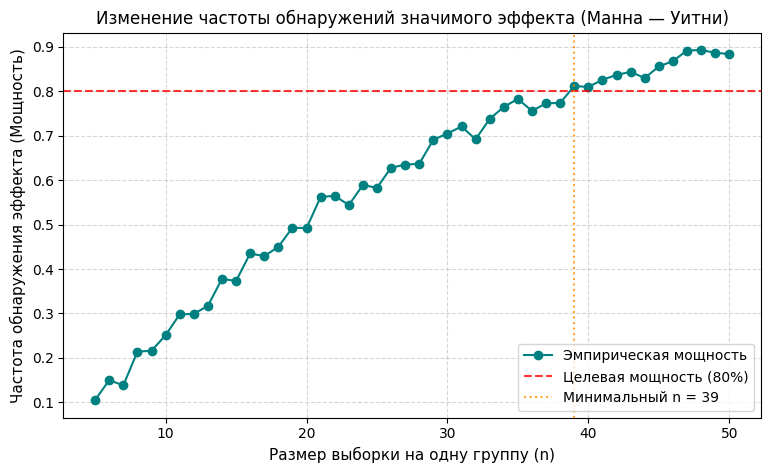

In [ ]:
diff = 0.5
effect = diff

size = None
n_simulations = 1000
alpha = 0.05
power_threshold = 0.80

sample_sizes = np.arange(5, 51, 1)
empirical_powers = []

for n in sample_sizes:
    significant_tests = 0
    for _ in range(n_simulations):
        control = np.random.lognormal(mean=2.5, sigma=0.75, size=n)
        test = np.random.lognormal(mean=2.5 - effect, sigma=0.75, size=n)

        _, p_value = stats.mannwhitneyu(control, test, alternative='two-sided')
        if p_value < alpha:
            significant_tests += 1

    current_power = significant_tests / n_simulations
    empirical_powers.append(current_power)

    if current_power >= power_threshold and size is None:
        size = n

int(np.ceil(size))

plt.figure(figsize=(9, 5))
plt.plot(sample_sizes, empirical_powers, marker='o', color='teal', label='Эмпирическая мощность')
plt.axhline(y=power_threshold, color='red', linestyle='--', alpha=0.8, label='Целевая мощность (80%)')
plt.axvline(x=size, color='darkorange', linestyle=':', alpha=0.8, label=f'Минимальный n = {size}')

plt.title("Изменение частоты обнаружений значимого эффекта (Манна — Уитни)", fontsize=12)
plt.xlabel("Размер выборки на одну группу (n)", fontsize=11)
plt.ylabel("Частота обнаружения эффекта (Мощность)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.show()